# Jersey City Citi Bike | Reproducible Demand Analysis

**A reusable educational companion to the WCTR 2026 research project.**

This notebook uses the project's provided, preprocessed 2024 Jersey City station data. It explores demand patterns and compares simple prediction baselines with demographic and seasonal features. It **does not claim** to reproduce every model or figure from the original WCTR paper; see `main_analysis.ipynb` for the historical research notebook.

**How to run:** Install packages in `requirements.txt`, then run all cells from top to bottom from any working directory within the project. Python 3.10+ recommended. No API keys required.

**Interpretation:** Observational associations are not causal; these covariates alone cannot establish potential demand at an unbuilt station. The station-month holdout used below tests prediction for *previously unseen stations*, not future-year forecasting.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Locate data no matter whether notebook is opened from project root or notebooks/.
def project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    return next((d for d in candidates if (d / 'data' / 'filtered_dataset.csv').is_file()), None)

ROOT = project_root()
if ROOT is None:
    # Standalone download: place both CSV files alongside this notebook.
    ROOT = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / 'filtered_dataset.csv').is_file()), None)
    if ROOT is None:
        raise FileNotFoundError('Place filtered_dataset.csv and dataset_with_log_sqrt_population_income329.csv alongside this notebook, or open the complete project ZIP.')
    DATA = ROOT
else:
    DATA = ROOT / 'data'
monthly = pd.read_csv(DATA / 'filtered_dataset.csv')
station = pd.read_csv(DATA / 'dataset_with_log_sqrt_population_income329.csv')
print('Monthly:', monthly.shape, '| Station-level:', station.shape)
print('Months:', sorted(monthly['month'].unique()), '| Stations:', monthly['start_station_id'].nunique())

Monthly: (636, 8) | Station-level: (53, 11)
Months: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)] | Stations: 53


## 1 · Data provenance and validation

`filtered_dataset.csv` contains station-month observations; `dataset_with_log_sqrt_population_income329.csv` contains station-level aggregates and transformations. They were provided from the original research workflow. Their exact extraction and geospatial join steps are **not** reproduced here because the raw trip and Census source files were not included.

In [2]:
required = {'start_station_id', 'start_station_name', 'number_of_origins', 'month', 'TOTAL_POP', 'IncomeMed'}
assert required.issubset(monthly.columns), f'Missing columns: {required - set(monthly.columns)}'
assert not monthly[list(required)].isna().any().any(), 'Missing required inputs'
assert monthly['month'].between(1, 12).all()
assert (monthly[['number_of_origins', 'TOTAL_POP', 'IncomeMed']] >= 0).all().all()
print(monthly[['number_of_origins', 'TOTAL_POP', 'IncomeMed']].describe().round(1))

       number_of_origins  TOTAL_POP  IncomeMed
count              636.0      636.0      636.0
mean               879.7    16997.9   121901.2
std                722.3     5344.1    45149.1
min                 27.0     3958.0    60910.0
25%                406.8    13947.0    77304.0
50%                678.5    16947.0   139091.0
75%               1171.5    20430.0   158631.0
max               5006.0    28285.0   196103.0


## 2 · Explore the data

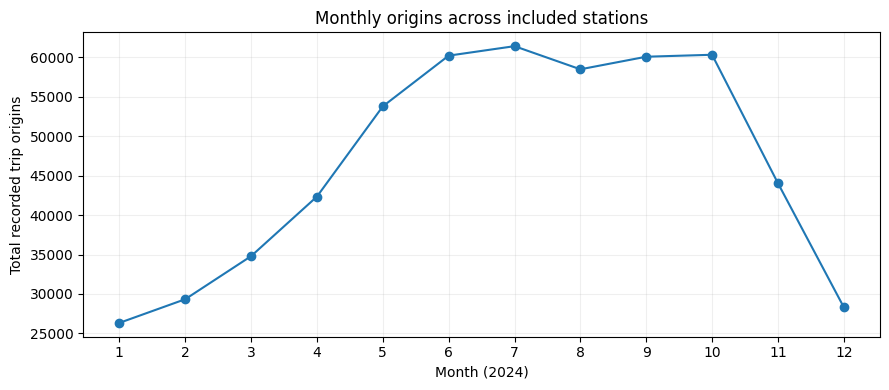

Top 10 stations by origins across available months:


,number_of_origins
start_station_name,
Grove St PATH,47128
Newport PATH,24443
Hamilton Park,22227
Exchange Pl,22200
Bergen Ave & Sip Ave,21146
Newport Pkwy,20293
Marin Light Rail,18482
Hoboken Ave at Monmouth St,17449
Columbus Drive,16705


In [3]:
monthly_totals = monthly.groupby('month', as_index=False)['number_of_origins'].sum()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly_totals['month'], monthly_totals['number_of_origins'], marker='o')
ax.set(xlabel='Month (2024)', ylabel='Total recorded trip origins', title='Monthly origins across included stations')
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print('Top 10 stations by origins across available months:')
display(monthly.groupby('start_station_name')['number_of_origins'].sum().sort_values(ascending=False).head(10).to_frame())

## 3 · Predict ridership for held-out stations

**Why the split matters:** Every station appears in multiple months. A random row-level train/test split would allow the same station into both sets and make the evaluation overly optimistic. We split by station ID, so no station appears in both training and testing. This is a more meaningful generalization check, though still not an unbiased measure of demand for a never-built station.

Models: (1) mean-only baseline, (2) regularized linear regression, and (3) random forest. Features are population, median income, and month. Station ID/name are deliberately excluded as features.

In [4]:
FEATURES = ['TOTAL_POP', 'IncomeMed', 'month']
X = monthly[FEATURES].copy()
y = monthly['number_of_origins'].astype(float)
groups = monthly['start_station_id'].astype(str)
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
print(f'Train stations: {groups.iloc[train_idx].nunique()}, test stations: {groups.iloc[test_idx].nunique()}')

Train stations: 42, test stations: 11


In [5]:
numeric_features = ['TOTAL_POP', 'IncomeMed']
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), numeric_features),
    ('month', OneHotEncoder(handle_unknown='ignore'), ['month'])
])
models = {
    'Train mean': DummyRegressor(strategy='mean'),
    'Ridge regression': Pipeline([('preprocess', preprocessor), ('model', Ridge(alpha=10.0))]),
    'Random forest': Pipeline([('preprocess', preprocessor), ('model', RandomForestRegressor(
        n_estimators=150, min_samples_leaf=3, random_state=42, n_jobs=-1))]),
}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = np.clip(model.predict(X_test), 0, None)
    predictions[name] = preds
    results.append({'model': name,
                    'MAE': mean_absolute_error(y_test, preds),
                    'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
                    'R2': r2_score(y_test, preds)})
score_table = pd.DataFrame(results).sort_values('MAE')
display(score_table.round(3))

,model,MAE,RMSE,R2
2,Random forest,361.988,478.930,0.365
0,Train mean,478.103,604.118,-0.010
1,Ridge regression,490.607,622.181,-0.072


## 4 · Visualize held-out predictions

Lower MAE/RMSE indicates better performance, and R² may be negative if a model is worse than predicting the held-out mean. These scores apply **only to this one held-out-station split** and are not the published WCTR metrics.

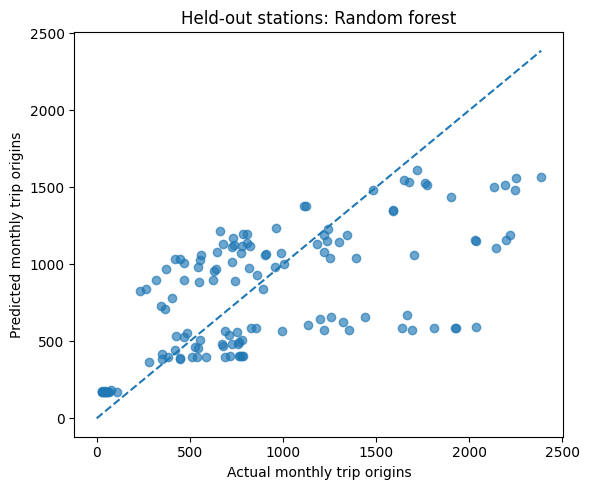

In [6]:
best_name = score_table.iloc[0]['model']
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, predictions[best_name], alpha=0.65)
lim = max(float(y_test.max()), float(np.max(predictions[best_name])))
ax.plot([0, lim], [0, lim], linestyle='--')
ax.set(xlabel='Actual monthly trip origins', ylabel='Predicted monthly trip origins',
       title=f'Held-out stations: {best_name}')
plt.tight_layout()
plt.show()

## 5 · Limitations and opportunities for adaptation

- **Inputs:** This repository includes preprocessed station-level Census and ridership features, not raw original trip records or GIS source geometry. Verify their coverage and sourcing before using them for new locations.
- **External validity:** A high-demand existing station may reflect job density, walkability, transit connections, cycling infrastructure, and current network placement—variables not in these baseline models.
- **No new-station causal effect:** Predicted trips do not equal the trips that *would be generated* by installing a new station. The model is descriptive/predictive on observed stations.
- **Validation:** A more robust extension would use repeated group splits, time-based validation on future months/years, spatial covariates, and uncertainty intervals.
- **Reusing in another city:** Replace both input files with similarly defined station-month records, check consistent geography and demographic joins, and rerun the full notebook.

**Research attribution:** Original Citi Bike spatial equity and demand forecasting research presented at WCTR 2026. The model comparison in this notebook is a separately prepared, reproducible demonstration built on the uploaded preprocessed dataset.